# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

**Question.** A fish-export cooperative in Jinja wants to know **(a)** whether its harvesting rate is sustainable and **(b)** how risky its revenue is. The older approach used Fibonacci numbers for the stock and flagged risk when revenue variance exceeded 50,000. This notebook replaces it with a logistic stock model, a bounded random-walk price model and a coefficient-of-variation (CV) risk rule, and explains why the old method fails.

**Organisation.** Reusable logic is in `src/` (`fish.py`, `price.py`, `risk.py`, `fish_plotting.py`); this notebook calls it and interprets the results. It runs top to bottom with *Restart & Run All*; all randomness uses `np.random.default_rng` with fixed seeds.

**Parameters from the brief:** r = 0.4 per week, K = 10,000 t, N(0) = 4,000 t, 52 weeks, start price UGX 12,000/kg with bounds 9,000–16,000. **Price volatility (UGX 400 per week) and the risk thresholds are my assumptions**, stated where used.

In [1]:
# Locate the repo root (the folder containing src/) so imports work wherever Jupyter was launched.
import os, sys
from pathlib import Path
for _root in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (_root / "src" / "fish.py").exists():
        os.chdir(_root)
        sys.path.insert(0, str(_root))
        break
else:
    raise FileNotFoundError(
        "Cannot find the 'src/' folder. Open this notebook from inside the project "
        "repository (keep src/ next to the notebook)."
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.fish import FishStock, fibonacci_sequence
from src.price import PriceModel
from src.risk import (RiskAssessor, weekly_revenue, annual_revenue, revenue_by_year, describe_revenue)
from src.fish_plotting import (plot_stock_trajectories, plot_revenue_histogram,
                               plot_price_paths, plot_closed_season)

SEED_PRICE, SEED_5Y = 2026, 2027       # fixed seeds
N_PATHS = 10_000                       # Monte Carlo price paths (brief asks for >= 1,000)
WEEKS = 52
HARVEST_RATES = [0.05, 0.10, 0.20, 0.30]

fish = FishStock(r=0.4, carrying_capacity=10_000, initial_stock=4_000)
price_model = PriceModel(start=12_000, lower=9_000, upper=16_000, weekly_volatility=400, seed=SEED_PRICE)
assessor = RiskAssessor(low=0.10, high=0.25, var_level=0.05)
os.makedirs("figures", exist_ok=True)
pd.options.display.float_format = "{:,.2f}".format
print(fish, "\n", price_model, "\n", assessor)

FishStock(r=0.4, K=10,000, N0=4,000) 
 PriceModel(start=12,000, bounds=(9,000, 16,000), vol=400, seed=2026) 
 RiskAssessor(low=0.1, high=0.25, var_level=0.05)


## Task 1 — Fibonacci baseline

In [2]:
fib = fibonacci_sequence(15)
print("15 Fibonacci numbers:", fib)
print(f"Ratio of the last two terms: {fib[-1] / fib[-2]:.4f}  (golden ratio = {(1 + 5 ** 0.5) / 2:.4f})")

terms = fibonacci_sequence(30)
first_over_K = next(i + 1 for i, v in enumerate(terms) if v > fish.K)
print(f"The sequence first exceeds K = {fish.K:,.0f} t at term number {first_over_K} ({terms[first_over_K - 1]:,})")

15 Fibonacci numbers: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]
Ratio of the last two terms: 1.6180  (golden ratio = 1.6180)
The sequence first exceeds K = 10,000 t at term number 22 (10,946)


Fibonacci numbers grow without limit, by a factor that settles at about 1.618 every step, so as a "stock" they would pass the lake's 10,000-tonne carrying capacity by the 22nd term and keep rising for ever. A real fish population is limited by food, habitat and oxygen, so its growth must slow as it approaches K (density dependence), which the sequence cannot express. The sequence can never fall, so it ignores harvesting, predation, disease and bad years, and it contains no randomness. Its growth rate is the same whatever the stock size, whereas real recruitment depends on the number of breeding fish and on the environment. It is therefore a number pattern and not a biological model, and the logistic equation with harvesting below replaces it.

## Task 2 — `FishStock`: logistic growth with harvesting

$$N_{t+1} = N_t + r\,N_t\left(1-\frac{N_t}{K}\right) - h\,N_t$$

`FishStock` validates its parameters, simulates a given number of weeks (optionally with a closed season) and also exposes the theory: the long-run stock $K(1-h/r)$, the maximum sustainable yield $rK/4$ and a sustainability status. Below, a 52-week run with h = 0.10.

In [3]:
stock, catch = fish.simulate(harvest_rate=0.10, weeks=WEEKS)
weeks_shown = [0, 1, 2, 4, 8, 13, 26, 39, 51]
display(pd.DataFrame({"week": weeks_shown,
                      "stock at start of week (t)": stock[weeks_shown],
                      "catch that week (t)": catch[weeks_shown]}).set_index("week"))
print(f"Stock after 52 weeks: {stock[-1]:,.2f} t | theory K(1 - h/r) = {fish.equilibrium_stock(0.10):,.2f} t")
print(f"Total catch in the year: {catch.sum():,.0f} t")

,stock at start of week (t),catch that week (t)
week,,
0,"4,000.00",400.00
1,"4,560.00",456.00
2,"5,096.26",509.63
4,"6,013.89",601.39
8,"7,052.89",705.29
13,"7,419.23",741.92
26,"7,499.21",749.92
39,"7,499.99",750.00
51,"7,500.00",750.00


Stock after 52 weeks: 7,500.00 t | theory K(1 - h/r) = 7,500.00 t
Total catch in the year: 37,363 t


The stock climbs from 4,000 t and settles at 7,500 t = K(1 − h/r), exactly the theoretical equilibrium. Growth is fastest when the stock is well below K, which is why the stock rises quickly at first and then flattens.

## Task 3 — `PriceModel`: a seeded, bounded random walk

Each week the price changes by a Normal(0, UGX 400) shock (about 3.3 % of the starting price; my assumption) and is **clipped to [9,000, 16,000] at every step**. Clipping step by step keeps the walk genuinely bounded: it can move back from a bound at once. (Clipping a whole unbounded path only at the end would let a hidden walk drift far outside the bounds and then stick to them.) Weekly revenue = harvest in kg × price.

Shape: (10000, 52) | first week: {np.float64(12000.0)}
Range: 9,000 to 16,000 | mean 12,087 UGX/kg
Share of all weeks sitting exactly on a bound: 3.7%
Reproducible with the same seed: True


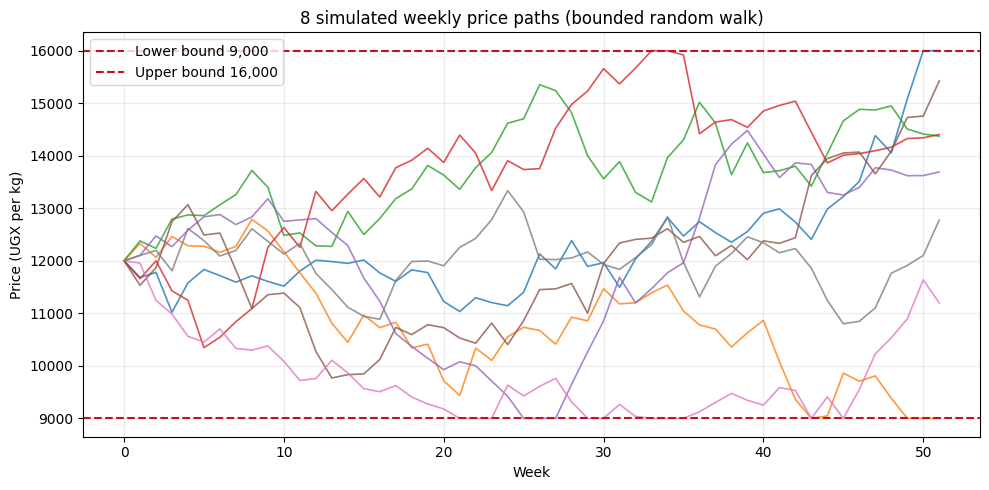

In [4]:
prices = price_model.simulate_paths(N_PATHS, WEEKS)          # shape (10000, 52): one row per price path
print("Shape:", prices.shape, "| first week:", set(prices[:, 0]))
print(f"Range: {prices.min():,.0f} to {prices.max():,.0f} | mean {prices.mean():,.0f} UGX/kg")
print(f"Share of all weeks sitting exactly on a bound: {np.mean((prices == 9_000) | (prices == 16_000)):.1%}")
print("Reproducible with the same seed:", np.array_equal(prices, price_model.simulate_paths(N_PATHS, WEEKS)))

fig = plot_price_paths(prices, 9_000, 16_000)
fig.savefig("figures/fish_price_paths.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 4 — Descriptive statistics of weekly revenue, and why a variance threshold of 50,000 is meaningless

One seeded price path (the first of the simulated paths) combined with the h = 0.10 catch gives a 52-week revenue series, summarised below with the `statistics` module.

In [5]:
price_path = prices[0]
wk_rev = weekly_revenue(catch, price_path)              # UGX per week
d = describe_revenue(wk_rev)
display(pd.DataFrame({"value": [d["mean"], d["median"], d["variance"], d["stdev"], d["cv"]],
                      "unit": ["UGX", "UGX", "UGX²", "UGX", "unitless"]},
                     index=["mean", "median", "variance", "standard deviation", "CV"]).style.format({"value": "{:,.4g}"}))

# The same data expressed in different units
rows = []
for unit, div in [("UGX", 1), ("UGX million", 1e6), ("UGX billion", 1e9)]:
    s = describe_revenue(wk_rev / div)
    rows.append({"unit": unit, "variance (unit²)": s["variance"], "st. dev. (unit)": s["stdev"], "CV": s["cv"]})
display(pd.DataFrame(rows).set_index("unit").style.format({"variance (unit²)": "{:,.4g}", "st. dev. (unit)": "{:,.4g}", "CV": "{:.4f}"}))
print(f"A variance of 50,000 UGX² corresponds to a standard deviation of only UGX {50_000 ** 0.5:,.0f} per week.")

,value,unit
mean,8.862e+09,UGX
median,8.893e+09,UGX
variance,1.851e+18,UGX²
standard deviation,1.36e+09,UGX
CV,0.1535,unitless


,variance (unit²),st. dev. (unit),CV
unit,,,
UGX,1.851e+18,1.36e+09,0.1535
UGX million,1.851e+06,"1,360",0.1535
UGX billion,1.851,1.36,0.1535


A variance of 50,000 UGX² corresponds to a standard deviation of only UGX 224 per week.


**Why the 50,000 threshold is meaningless.** Variance is measured in the **square** of the revenue unit (UGX²), so its value depends entirely on the unit chosen: the same data have variance 1.85 × 10¹⁸ in UGX² but only about 1.85 in UGX-billion², while the CV stays at 15.4 % in every case. A fixed cut-off of 50,000 therefore has no meaning without a unit, and in UGX² it corresponds to a standard deviation of just UGX 224 on weekly revenues of billions, so *every* realistic scenario would be flagged "risky". It also ignores scale: a larger cooperative has a larger variance for the same relative risk. The **CV** (standard deviation ÷ mean) is unit-free and comparable across scenarios, which is why it is used for the risk rule.

(This weekly CV of 15.4 % also contains the upward trend of catch as the stock recovers during the year. The risk rule in Task 5 therefore uses *annual* revenue across many price paths, which measures price uncertainty alone.)

## Task 5 — `RiskAssessor` and a Monte Carlo Value-at-Risk

**Rule** (CV of simulated annual revenue): **Low** if CV < 0.10, **Moderate** if 0.10 ≤ CV < 0.25, **High** if CV ≥ 0.25.

**Justification.** For roughly bell-shaped revenue, the worst 5 % of years fall about 1.645 × CV below the mean. A CV of 0.10 therefore means a bad year loses about 16 % of expected revenue (a modest reserve can absorb it); a CV of 0.25 means about 41 % (a bad year could threaten fixed costs such as wages and boats). The thresholds are a planning judgement, not a law, and can be changed in the constructor.

**Value-at-Risk.** 10,000 simulated price paths give 10,000 possible annual revenues. The 5 % VaR is reported two ways: the **5th-percentile revenue** (95 % of years do better than this) and the **shortfall** against expected revenue (mean − 5th percentile).

In [6]:
stock, catch = fish.simulate(0.10, WEEKS)
rev10 = annual_revenue(catch, prices)             # 10,000 annual revenues
rep = assessor.assess(rev10)
display(pd.Series({
    "mean annual revenue (UGX bn)": rep.mean / 1e9,
    "st. dev. (UGX bn)": rep.stdev / 1e9,
    "CV": rep.cv,
    "risk class": rep.risk_class,
    "5th-percentile revenue (UGX bn)": rep.percentile_5 / 1e9,
    "5% VaR = mean - 5th pct (UGX bn)": rep.value_at_risk / 1e9,
    "VaR as % of mean revenue": rep.var_fraction * 100,
    "rule of thumb 1.645 x CV (%)": 1.645 * rep.cv * 100,
}, name="h = 0.10").to_frame().astype(str))

,h = 0.10
mean annual revenue (UGX bn),451.74288959790596
st. dev. (UGX bn),51.90142164161524
CV,0.1148915076180002
risk class,Moderate
5th-percentile revenue (UGX bn),373.64950170546666
5% VaR = mean - 5th pct (UGX bn),78.09338789243927
VaR as % of mean revenue,17.28713161638245
rule of thumb 1.645 x CV (%),18.89965300316103


At h = 0.10 the expected annual revenue is about UGX 452 billion with a CV of 11.5 %, which is **Moderate**. In one year in twenty, revenue falls below **UGX 374 billion**, a **5 % VaR of about UGX 78 billion (17 % of expected revenue)**. The rule-of-thumb figure (1.645 × CV ≈ 19 %) is slightly higher than the simulated 17 % because the bounded price distribution has thinner tails than a bell curve.

## Task 6 — Scenario analysis against the theoretical maximum sustainable yield

For h = 0.05, 0.10, 0.20, 0.30: final stock, annual catch and revenue, CV, risk class and VaR, compared with MSY = rK/4 = **1,000 t per week (52,000 t per year)**, which is reached at h = r/2 = 0.20 with stock K/2 = 5,000 t.

In [7]:
rows, results = [], {}
for h in HARVEST_RATES:
    s, c = fish.simulate(h, WEEKS)
    rev = annual_revenue(c, prices)
    r_ = assessor.assess(rev)
    results[h] = {"stock": s, "catch": c, "rev": rev, "report": r_}
    rows.append({
        "h": h,
        "final stock (t)": s[-1],
        "long-run stock K(1-h/r) (t)": fish.equilibrium_stock(h),
        "year-1 catch (t)": c.sum(),
        "last-week catch (t)": c[-1],
        "last-week catch as % of MSY": c[-1] / fish.msy * 100,
        "mean revenue (UGX bn)": r_.mean / 1e9,
        "CV": r_.cv,
        "risk class": r_.risk_class,
        "5% VaR (UGX bn)": r_.value_at_risk / 1e9,
        "sustainability": fish.sustainability_status(h),
    })
scenario_df = pd.DataFrame(rows).set_index("h")
display(scenario_df.style.format({"final stock (t)": "{:,.0f}", "long-run stock K(1-h/r) (t)": "{:,.0f}",
        "year-1 catch (t)": "{:,.0f}", "last-week catch (t)": "{:,.0f}", "last-week catch as % of MSY": "{:.0f}",
        "mean revenue (UGX bn)": "{:,.1f}", "CV": "{:.3f}", "5% VaR (UGX bn)": "{:,.1f}"}))
print(f"MSY = rK/4 = {fish.msy:,.0f} t/week = {fish.msy * 52:,.0f} t/year; MSY harvest rate r/2 = {fish.msy_harvest_rate}")
print(f"Long-run weekly catch at h = 0.10: {fish.equilibrium_catch(0.10):,.0f} t; at h = 0.30: {fish.equilibrium_catch(0.30):,.0f} t")

,final stock (t),long-run stock K(1-h/r) (t),year-1 catch (t),last-week catch (t),last-week catch as % of MSY,mean revenue (UGX bn),CV,risk class,5% VaR (UGX bn),sustainability
h,,,,,,,,,,
0.050000,"8,750","8,750","21,715",437,44,262.6,0.115,Moderate,45.6,sustainable
0.100000,"7,500","7,500","37,363",750,75,451.7,0.115,Moderate,78.1,sustainable
0.200000,"5,000","5,000","50,872","1,000",100,615.0,0.113,Moderate,104.5,sustainable
0.300000,"2,504","2,500","42,461",751,75,513.0,0.106,Moderate,82.1,overfishing


MSY = rK/4 = 1,000 t/week = 52,000 t/year; MSY harvest rate r/2 = 0.2
Long-run weekly catch at h = 0.10: 750 t; at h = 0.30: 750 t


**Comparison with MSY.**
- **h = 0.20 is the MSY harvest rate**: the stock settles at 5,000 t and the weekly catch reaches 1,000 t, 100 % of MSY, giving the highest revenue (about UGX 615 bn).
- **h = 0.05 and 0.10 are sustainable but under-use the lake**: their long-run weekly catches are 437 t and 750 t (44 % and 75 % of MSY) from larger stocks.
- **h = 0.30 is overfishing**: the stock falls to about 2,500 t, below K/2. Its long-run weekly catch (750 t) is exactly the same as at h = 0.10, but it takes it from a stock one third the size, which is more fragile and gives no extra catch. In year 1 it looks better (UGX 513 bn against 452 bn) only because it harvests the initial stock faster.
- **h ≥ 0.40 = r would collapse the stock** (the model's equilibrium is zero).

**Risk class.** All four scenarios are **Moderate** with a CV of about 11 %. This is expected: the fish stock is deterministic here, so the only randomness is the price, and relative price risk hardly changes with the harvest rate. The CV therefore measures *price* risk only; what separates the scenarios is the **sustainability status** and the absolute VaR (which grows with revenue).

## Task 7 — Figures

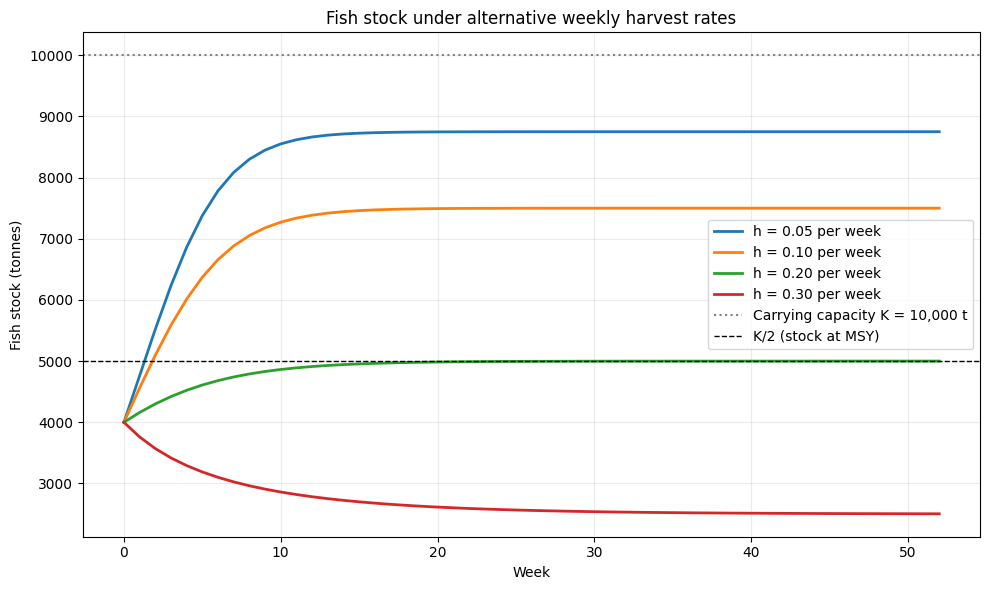

In [8]:
fig = plot_stock_trajectories({h: results[h]["stock"] for h in HARVEST_RATES}, fish.K)
fig.savefig("figures/fish_stock_trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

Each curve converges to its theoretical level K(1 − h/r). Only h = 0.05 and 0.10 stay above the K/2 line; h = 0.20 sits on it (the MSY stock) and h = 0.30 drops below it.

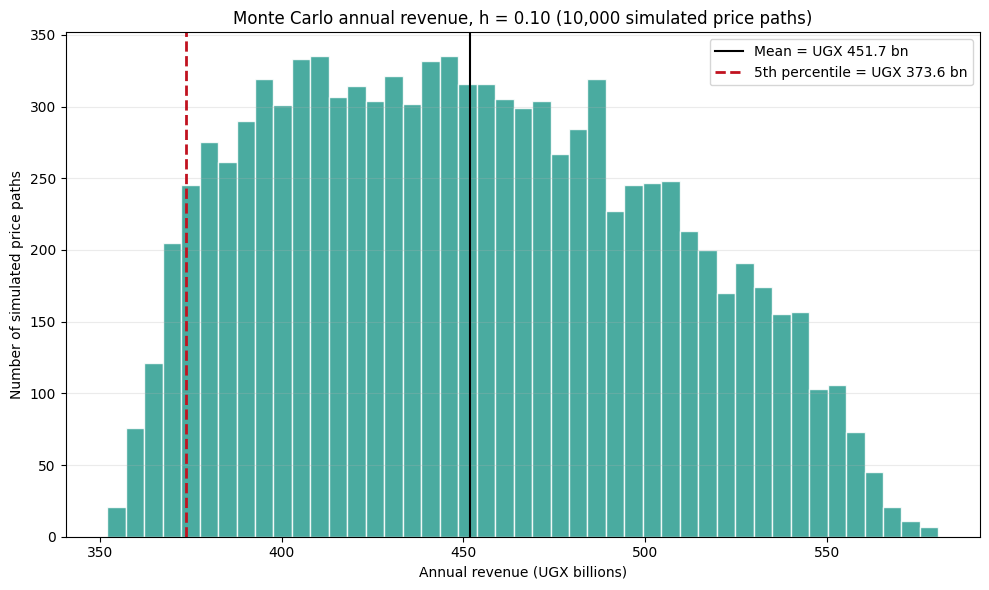

In [9]:
rep10 = results[0.10]["report"]
fig = plot_revenue_histogram(results[0.10]["rev"], rep10.mean, rep10.percentile_5,
                             "Monte Carlo annual revenue, h = 0.10 (10,000 simulated price paths)")
fig.savefig("figures/fish_revenue_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

The histogram is roughly bell-shaped around UGX 452 billion; the red line marks the 5th percentile (about UGX 374 billion), the revenue level that is beaten in 95 % of simulated years.

## Extension — An 8-week closed season over 5 years

No harvesting during the **first 8 weeks of every 52-week year**. Five years (260 weeks) are simulated for all four harvest rates, with the same 10,000 price paths in both cases so that the comparison is fair. "Long-run" revenue is the average annual revenue in years 3–5, after the start-up transient.

,"5-yr revenue, no closure (bn)","5-yr revenue, closure (bn)",5-yr change (%),"long-run revenue per year, no closure (bn)","long-run revenue per year, closure (bn)",long-run change (%),mean stock no closure (t),mean stock closure (t)
h,,,,,,,,
0.050000,"1,389.2","1,196.1",-13.9,282.5,241.1,-14.7,"8,670.7","8,858.4"
0.100000,"2,383.2","2,075.4",-12.9,484.4,418.4,-13.6,"7,437.3","7,809.3"
0.200000,"3,190.2","2,906.2",-8.9,645.8,585.9,-9.3,"4,978.4","5,705.3"
0.300000,"2,444.5","2,591.8",6.0,484.4,521.6,7.7,"2,544.3","3,597.0"


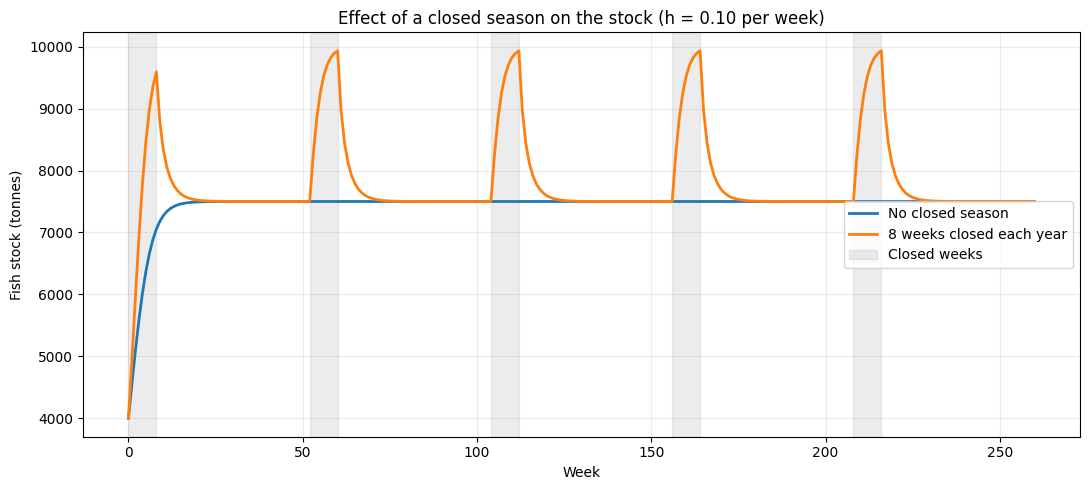

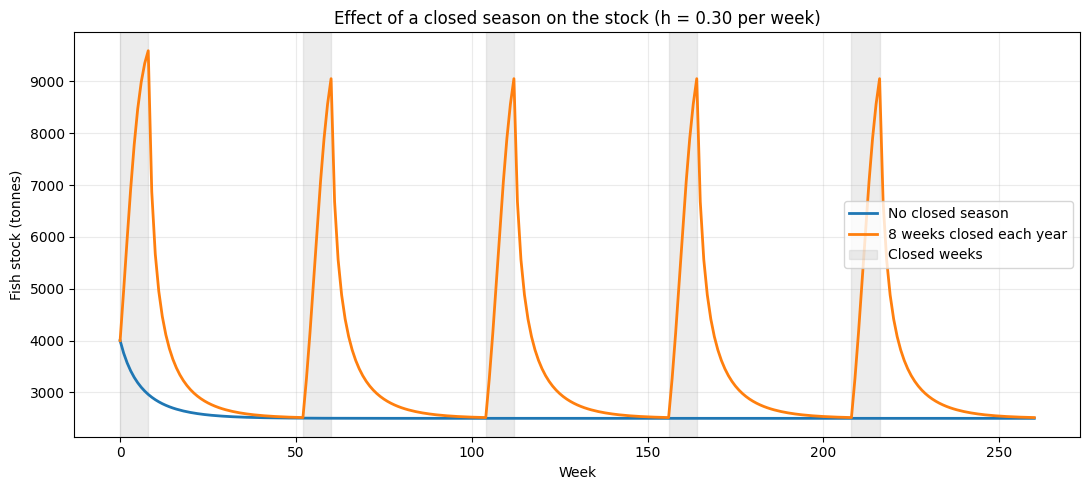

In [10]:
paths5 = price_model.simulate_paths(N_PATHS, 5 * 52, seed=SEED_5Y)
rows = []
for h in HARVEST_RATES:
    out = {}
    for cw in (0, 8):
        s, c = fish.simulate(h, 5 * 52, closed_weeks=cw)
        by_year = revenue_by_year(c, paths5)                  # (paths, 5 years)
        out[cw] = {"total": by_year.sum(axis=1).mean(), "longrun": by_year[:, 2:].mean(),
                   "mean_stock": s.mean(), "catch": c.sum()}
    rows.append({
        "h": h,
        "5-yr revenue, no closure (bn)": out[0]["total"] / 1e9,
        "5-yr revenue, closure (bn)": out[8]["total"] / 1e9,
        "5-yr change (%)": (out[8]["total"] / out[0]["total"] - 1) * 100,
        "long-run revenue per year, no closure (bn)": out[0]["longrun"] / 1e9,
        "long-run revenue per year, closure (bn)": out[8]["longrun"] / 1e9,
        "long-run change (%)": (out[8]["longrun"] / out[0]["longrun"] - 1) * 100,
        "mean stock no closure (t)": out[0]["mean_stock"],
        "mean stock closure (t)": out[8]["mean_stock"],
    })
closure_df = pd.DataFrame(rows).set_index("h")
display(closure_df.style.format("{:,.1f}"))

for h in (0.10, 0.30):
    s_open, _ = fish.simulate(h, 5 * 52)
    s_shut, _ = fish.simulate(h, 5 * 52, closed_weeks=8)
    fig = plot_closed_season(s_open, s_shut, 8, h)
    fig.savefig(f"figures/fish_closed_season_h{int(h * 100):02d}.png", dpi=150, bbox_inches="tight")
    plt.show()

**Result.** The effect of a closed season depends on whether the stock is healthy:

- **At h = 0.05, 0.10 and 0.20 it costs revenue**: −14 %, −13 % and −9 % over five years (long run: −15 %, −14 %, −9 %). The stock is already healthy, so the 8 closed weeks (15 % of the year) just lose catch. The stock rebounds during the break but is fished back to the same equilibrium within weeks, which is why the final stock is essentially the same with and without closure (7,500 t at h = 0.10), and only the mean stock over the year is a little higher.
- **At h = 0.30 it raises revenue**: **+6 % over five years and +7.7 % in the long run**. The stock is depleted (about 2,500 t); during the 8 closed weeks it rebuilds to about 9,000 t, and after reopening a burst of fishing (up to about 2,700 t in a single week, against a normal 750 t) harvests it. Within about 13 weeks the stock is back near 2,500 t (see the second figure), so the gain comes from a **boom-and-bust catch pulse**, not from a permanently healthier lake. The higher mean stock (2,544 → 3,597 t) is only the effect of those spikes.

**Practical conclusion.** A closed season is a remedy for overfishing, not a gain for a sustainable harvest rate. Even at h = 0.30 it only brings long-run revenue to about UGX 522 bn per year, well below the UGX 646 bn a year earned by simply fishing at h = 0.20. Lowering the harvest rate beats closing the season, and the closed-season gain would also need boats and processing able to land weeks of three to four times the normal catch.

## Sanity checks (hand calculations / second method)

In [11]:
# 1. First week by hand: N1 = 4000 + 0.4*4000*(1 - 4000/10000) - 0.1*4000 = 4560
s10, c10 = fish.simulate(0.10, 52)
assert np.isclose(s10[1], 4000 + 0.4 * 4000 * (1 - 0.4) - 0.1 * 4000) and np.isclose(s10[1], 4560)

# 2. Long-run stock matches the closed-form K(1 - h/r) for every sustainable scenario
for h in (0.05, 0.10, 0.20):
    long_run, _ = fish.simulate(h, 400)
    assert np.isclose(long_run[-1], fish.K * (1 - h / fish.r), rtol=1e-6)

# 3. MSY: the largest long-run weekly catch over a fine grid of h is rK/4 at h = r/2
grid = np.linspace(0, 0.4, 401)
assert np.isclose(max(fish.equilibrium_catch(h) for h in grid), fish.msy)
assert np.isclose(grid[np.argmax([fish.equilibrium_catch(h) for h in grid])], 0.2)

# 4. Week-0 revenue by hand: 400 t x 1,000 kg/t x UGX 12,000/kg = UGX 4.8 bn
assert np.isclose(weekly_revenue(c10, prices[0])[0], 400 * 1_000 * 12_000)

# 5. VaR by hand from the simulated revenues
assert np.isclose(rep.value_at_risk, rev10.mean() - np.percentile(rev10, 5))

# 6. Prices obey the bounds and start at 12,000
assert prices.min() >= 9_000 and prices.max() <= 16_000 and np.all(prices[:, 0] == 12_000)
print("All sanity checks passed.")

All sanity checks passed.


## Findings & Limitations

**Findings.** The logistic model settles at K(1 − h/r): 8,750, 7,500, 5,000 and 2,500 t for h = 0.05, 0.10, 0.20 and 0.30. Yield peaks at h = r/2 = 0.20, where the weekly catch equals MSY = 1,000 t. Fishing at h = 0.30 is overfishing: it takes the same long-run catch as h = 0.10 (750 t a week) from a stock one third the size, and any h ≥ 0.40 collapses the stock. The 50,000 variance threshold is meaningless because variance is in UGX² and depends on the unit; the unit-free CV is about 11 % in every scenario, so all four are Moderate, and sustainability status, not CV, separates them. At h = 0.10 the 5 % VaR is UGX 78 bn, 17 % of expected annual revenue (UGX 452 bn). An 8-week closed season cuts long-run revenue by 9–15 % when h ≤ 0.20 but raises it by 7.7 % at h = 0.30, where the stock is depleted, through a boom-and-bust catch pulse after reopening; fishing at h = 0.20 is better still.

**Limitations.** The brief's parameters imply revenues of hundreds of billions of UGX a year, so the numbers are relative comparisons, not forecasts. Fish dynamics are deterministic and catch is proportional to stock with no capacity limit, so CV and VaR capture price risk only and closed-season catch pulses are landed too easily. Price volatility and the CV thresholds are my assumptions. There are no costs, taxes or discounting.